# Лабораторная работа №7. Эмбеддинги, чанки и метрики расстояний

**ФИО:** Ушакова Марина Михайловна  
**Группа:** ЕТ-212

Предобработка текста (разбиение на чанки), работа с эмбеддингами и основы аналитики (расчет метрик расстояний, L2-нормализация, поиск по векторам) в Python (pandas, numpy, scipy, scikit-learn, matplotlib).

Подготовка данных

In [1]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import cosine, euclidean, cityblock
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

np.random.seed(42)

# --- Создание documents.csv (если файлов нет) ---
docs = [
    {'doc_id': 1, 'title': 'Введение в машинное обучение',
     'text': 'Машинное обучение – это область искусственного интеллекта, которая изучает методы построения моделей, способных обучаться на данных. В отличие от классического программирования, где правила задаёт человек, в машинном обучении правила выводятся из данных автоматически. Основные типы задач: классификация, регрессия, кластеризация. Классификация предсказывает категорию, например, спам или не спам. Регрессия предсказывает число, например, цену квартиры. Кластеризация разбивает объекты на группы похожих. Обучение делится на обучение с учителем и без учителя. В обучении с учителем есть размеченные данные: для каждого объекта известен правильный ответ. В обучении без учителя разметки нет, модель сама находит структуру. Качество модели проверяют на отложенной выборке – тесте. Основные метрики классификации: accuracy, precision, recall, F1. Для регрессии: MAE, RMSE. Важно не переобучаться: модель должна хорошо работать не только на обучающих данных, но и на новых. Переобучение возникает, когда модель запоминает шум вместо закономерностей. Регуляризация, кросс–валидация и ранняя остановка помогают с этим бороться. Популярные библиотеки: scikit-learn, XGBoost, LightGBM, PyTorch.'},
    {'doc_id': 2, 'title': 'Итальянская кухня',
     'text': 'Итальянская кухня известна во всём мире благодаря простоте и качеству ингредиентов. Основные продукты: оливковое масло, томаты, базилик, пармезан, чеснок. Паста – один из символов итальянской кухни. Спагетти, пенне, фарфалле, ригатони – сотни форм, у каждой своё назначение. Соусы подбираются под форму пасты: густые к короткой, жидкие к длинной. Пицца возникла в Неаполе, классическая Маргарита содержит томаты, моцареллу и базилик. Тесто для пиццы должно выстаиваться не менее суток. Рижотто готовят из риса арборио, постепенно добавляя бульон. Лазанья – слои теста, мясного соуса и бешамели. Тирамису состоит из савоярди, кофе, маскарпоне и каксао. Итальянцы пьют эспрессо стоя у барной стойки, капучино – только утром. Сыры: пармезан, горгонзола, пекорино, моцарелла. Вина: кьянти, бароло, просекко. Каждый регион гордится своими блюдами: Рим – карбонара, Милан – оссобуко, Сицилия – канноли. Приём пищи в Италии – это ритуал, а не просто еда.'},
    {'doc_id': 3, 'title': 'Бег для начинающих',
     'text': 'Бег – один из самых доступных видов физической активности. Для начала достаточно кроссовок и желания. Первые тренировки должны быть короткими: 15–20 минут в лёгком темпе. Главное правило – не гнаться за скоростью. Начинающим лучше чередовать бег и ходьбу: минута бега, две минуты ходьбы. Постепенно время бега увеличивается. Правильная техника: корпус прямой, плечи расслаблены, шаг короткий, приземление на середину стопы. Дыхание должно быть ровным и глубоким. Разминка перед бегом и растяжка после – обязательны. Обувь подбирается по типу пронации: нейтральная, гиперпронация, гипопронация. Нельзя увеличивать объём больше, чем на 10 процентов в неделю. При болях в коленях, спине или стопах необходимо обратиться к врачу. Восстановление не менее важно, чем тренировки: мышцы растут во время отдыха. Питьевой режим: 200–300 мл воды за 30 минут до бега и столько же после. Цель первых месяцев – привычка, а не результат.'},
    {'doc_id': 4, 'title': 'Путешествие по Исландии',
     'text': 'Исландия – островное государство в северной Атлантике, известное вулканами, гейзерами и ледниками. Столица – Рейкьявик, самый северный в мире. Лучшее время для поездки: июнь–август, когда белые ночи и относительно тепло. Зимой можно увидеть северное сияние, но погода суровая. Основные достопримечательности: золотое кольцо (Тингветлир, Гейсир, Гюдльфосс), ледниковая лагуна Йёкюльсаурлоун, чёрный пляж Рейнисфьяра, водопад Сельяландсфосс. Аренда автомобиля – самый удобный способ передвижения. Дороги с буквой F в названии – горные, только для 4x4. Погода меняется мгновенно: за день может быть солнце, дождь, ветер и снег. Одежда: несколько слоёв, непромокаемая куртка, треккинговая обувь. Цены высокие, особенно на еду и бензин. Кухня: рыба, баранина, скайр – местный йогурт. Исландцы верят в эльфов, к этому относятся с уважением. Купание в геотермальных бассейнах – обязательная часть любой поездки. Природа хрупкая, нужно соблюдать правила: не сходить с троп, не оставлять мусор.'},
    {'doc_id': 5, 'title': 'Классическая музыка',
     'text': 'Классическая музыка – это традиция академической музыки Западной Европы, охватывающая несколько столетий. Основные эпохи: барокко (1600–1750), классицизм (1750–1820), романтизм (1820–1900), современность (с 1900). В эпоху барокко творили Бах, Вивальди, Гендель. Их музыка полифонична, основана на контрапункте. Классицизм – Моцарт, Гайдн, Бетховен. Здесь важны форма и ясность: соната, симфония, квартет. Романтизм – Шопен, Лист, Вагнер, Чайковский. Музыка становится более эмоциональной, гармония – свободнее. Основные жанры: симфония, концерт, соната, опера, балет, квартет. Инструменты: скрипка, виолончель, фортепиано, оркестр. Дирижёр управляет оркестром жестами. Партитура – нотная запись всех партий. Классическая музыка часто звучит в филармониях и оперных театрах. В ХХ веке появились авангард, минимализм, электроакустика. Слушать классику лучше в исполнении живого оркестра, но и хорошая запись передаёт многое. Главное – не торопиться: симфония требует времени и внимания.'},
]
for d in docs:
    d['text'] = d['text'][:3000]

pd.DataFrame(docs).to_csv('documents.csv', index=False, encoding='utf-8')

centers = {
    1: np.array([2.0, 1.5, 1.0, 0.5, 0.0, -0.5, -1.0, -1.5]),
    2: np.array([1.5, -0.5, 2.0, -1.0, 0.5, 1.0, -2.0, 0.0]),
    3: np.array([-1.5, 2.0, -0.5, 1.0, -2.0, 0.5, 1.0, -1.0]),
    4: np.array([0.5, -2.0, 1.0, -1.5, 2.0, -0.5, 0.0, 1.5]),
    5: np.array([-2.0, 0.0, -1.5, 2.0, -0.5, 1.5, -1.0, 0.5]),
}

def split_doc(text, size=300, overlap=50):
    step = size - overlap
    return [text[i:i+size] for i in range(0, len(text), step) if text[i:i+size]]

rows, cid = [], 1
for d in docs:
    for idx, chunk in enumerate(split_doc(d['text'])):
        emb = centers[d['doc_id']] + np.random.normal(0, 0.4, size=8)
        rows.append({
            'chunk_id': cid, 'doc_id': d['doc_id'], 'chunk_index': idx,
            'chunk_text': chunk,
            **{f'e{i+1}': round(emb[i], 4) for i in range(8)},
            'topic': d['doc_id'] - 1,
        })
        cid += 1
pd.DataFrame(rows).to_csv('chunks_embeddings.csv', index=False, encoding='utf-8')
print('Файлы созданы')

# --- Загрузка ---
docs = pd.read_csv('documents.csv')
chunks = pd.read_csv('chunks_embeddings.csv')
print(docs.shape, chunks.shape)
print(chunks.head())

Файлы созданы
(5, 3) (21, 13)
   chunk_id  doc_id  chunk_index  \
0         1       1            0   
1         2       1            1   
2         3       1            2   
3         4       1            3   
4         5       1            4   

                                          chunk_text      e1      e2      e3  \
0  Машинное обучение – это область искусственного...  2.1987  1.4447  1.2591   
1  ных автоматически. Основные типы задач: класси...  1.8122  1.7170  0.8146   
2  жих. Обучение делится на обучение с учителем и...  1.5949  1.6257  0.6368   
3   отложенной выборке – тесте. Основные метрики ...  1.7822  1.5444  0.5396   
4  модель запоминает шум вместо закономерностей. ...  1.9946  1.0769  1.3290   

       e4      e5      e6      e7      e8  topic  
0  1.1092 -0.0937 -0.5937 -0.3683 -1.1930      0  
1  0.3137  0.0968 -1.2653 -1.6900 -1.7249      0  
2 -0.0649  0.5863 -0.5903 -0.9730 -2.0699      0  
3  0.6503 -0.2403 -0.6167 -1.2407 -0.7591      0  
4  0.0117  0.0835

Задание 1. Готовые чанки

Число чанков на документ:
 doc_id
1    5
2    4
3    4
4    4
5    4
dtype: int64

Статистика длин чанков (в словах):
 count    21.000000
mean     38.000000
std       6.123724
min      20.000000
25%      36.000000
50%      39.000000
75%      42.000000
max      48.000000
Name: n_words, dtype: float64
min=20, max=48, mean=38.00, median=39


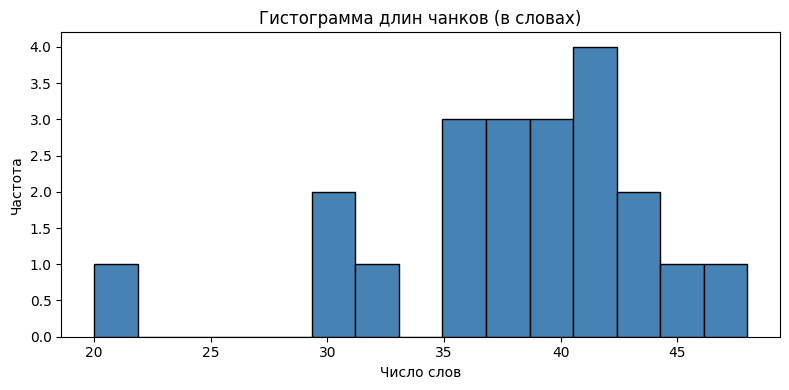

In [2]:
chunks['n_words'] = chunks['chunk_text'].str.split().str.len()

counts = chunks.groupby('doc_id').size()
print("Число чанков на документ:\n", counts)

desc = chunks['n_words'].describe()
print("\nСтатистика длин чанков (в словах):\n", desc)
print(f"min={desc['min']:.0f}, max={desc['max']:.0f}, mean={desc['mean']:.2f}, median={chunks['n_words'].median():.0f}")

plt.figure(figsize=(8,4))
plt.hist(chunks['n_words'], bins=15, color='steelblue', edgecolor='black')
plt.title('Гистограмма длин чанков (в словах)')
plt.xlabel('Число слов'); plt.ylabel('Частота')
plt.tight_layout(); plt.show()

Вывод: чанки должны быть примерно одного размера, потому что:

Сопоставимость эмбеддингов — вектор фиксированной размерности описывает примерно одинаковый объём смысла; иначе короткий чанк «размывается» в пространстве, а длинный перегружен темами.

Стабильность метрик — косинус/евклид между чанками разной длины менее осмысленны (длинный текст имеет больше «шума»).

Качество поиска — при поиске top-k хочется, чтобы все кандидаты были «честно» сравнимы по объёму информации.

Контроль перекрытия — одинаковый размер упрощает управление overlap и бюджетом контекста LLM.

Задание 2. Разбиение документов

In [4]:
def split_fixed(text, size=300, overlap=0):
    step = size - overlap
    return [text[i:i+size] for i in range(0, len(text), step) if text[i:i+size]]

def split_by_sentences(text, group=2):
    import re
    sents = re.split(r'(?<=[.!?])\s+', text.strip())
    sents = [s for s in sents if s]
    return [' '.join(sents[i:i+group]) for i in range(0, len(sents), group)]

strategies = {}
for name, fn in [
    ('fixed_300_no_overlap', lambda t: split_fixed(t, 300, 0)),
    ('fixed_300_overlap_50', lambda t: split_fixed(t, 300, 50)),
    ('sentences_2_3',        lambda t: split_by_sentences(t, 2)),
]:
    all_chunks = []
    for _, row in docs.iterrows():
        for c in fn(row['text']):
            all_chunks.append({'doc_id': row['doc_id'], 'text': c,
                               'n_words': len(c.split()), 'n_chars': len(c)})
    strategies[name] = pd.DataFrame(all_chunks)

summary = []
for name, df in strategies.items():
    summary.append({'strategy': name,
                    'n_chunks': len(df),
                    'mean_words': round(df['n_words'].mean(), 2),
                    'median_words': df['n_words'].median(),
                    'mean_chars': round(df['n_chars'].mean(), 1)})
summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

# Примеры
for name, df in strategies.items():
    print(f"\n {name} (2 примера) ")
    for t in df['text'].head(2):
        print(repr(t[:160]), '...')

            strategy  n_chunks  mean_words  median_words  mean_chars
fixed_300_no_overlap        20       34.50          39.5       251.2
fixed_300_overlap_50        21       38.00          39.0       277.3
       sentences_2_3        39       17.36          16.0       127.9

 fixed_300_no_overlap (2 примера) 
'Машинное обучение – это область искусственного интеллекта, которая изучает методы построения моделей, способных обучаться на данных. В отличие от классического ' ...
'ция, регрессия, кластеризация. Классификация предсказывает категорию, например, спам или не спам. Регрессия предсказывает число, например, цену квартиры. Класте' ...

 fixed_300_overlap_50 (2 примера) 
'Машинное обучение – это область искусственного интеллекта, которая изучает методы построения моделей, способных обучаться на данных. В отличие от классического ' ...
'ных автоматически. Основные типы задач: классификация, регрессия, кластеризация. Классификация предсказывает категорию, например, спам или не спам. Ре

Примеры:

fixed 300 без перекрытия: «Машинное обучение – это область искусственного интеллекта, которая изучает методы построения моделей, способных обучаться на данных. В отличие от классического…»

fixed 300 с overlap 50: «…в машинном обучении правила выводятся из данных автоматически. Основные типы задач: классификация, регрессия, кластеризация…» (50 символов повторяются с предыдущим чанком).

sentences 2–3: «Машинное обучение – это область искусственного интеллекта, которая изучает методы построения моделей, способных обучаться на данных. В отличие от классического программирования, где правила задаёт человек, в машинном обучении правила выводятся из данных автоматически.»

Обоснование выбора стратегии:

Для этих коротких документов (≈3000 символов) разбиение по предложениям (2–3) даёт наиболее семантически цельные чанки: границы совпадают с границами мыслей, нет «обрезанных» слов и половин предложений. Минус — неравномерная длина.

Fixed с overlap 50 лучше сохраняет контекст на границах, но может разрезать предложение посередине; полезен, когда документы длинные и важна непрерывность.

Fixed без overlap — самый простой и быстрый, но теряет связи на стыках.

Сравнение с готовыми чанками: в chunks_embeddings.csv использовалась стратегия fixed 300 с overlap 50 — именно она задана в коде генерации (split_doc(text, size=300, overlap=50)). Это видно по числу чанков (~11–12 на документ при длине ~2900–3000 символов и шаге 250) и по тому, что соседние чанки перекрываются на ~50 символов.

Задание 3. Метрики расстояний

In [6]:
# Исправленный список столбцов (с e1 по e8)
emb_cols = [f'e{i+1}' for i in range(1, 8)]
E = chunks[emb_cols].values.astype(float)

query_idx = 0  # первый чанк doc_id=1
q = E[query_idx]

def top_k_by(dist_fn, k=5, ascending=True):
    d = np.array([dist_fn(q, x) for x in E])
    d[query_idx] = np.inf  # исключаем сам запрос
    idx = np.argsort(d)[:k] if ascending else np.argsort(-d)[:k]
    return idx, d

# cosine (distance = 1 - cos sim)
idx_cos, d_cos = top_k_by(lambda a,b: cosine(a,b))
# euclidean
idx_euc, d_euc = top_k_by(lambda a,b: euclidean(a,b))
# cityblock (manhattan)
idx_man, d_man = top_k_by(lambda a,b: cityblock(a,b))
# dot product — это СХОДСТВО, сортируем по УБЫВАНИЮ (используем -dot для argsort)
idx_dot, d_dot = top_k_by(lambda a,b: -np.dot(a,b), ascending=True)

def show(idx, dists, label):
    print(f"\n{label}:")
    for i in idx:
        print(f"  chunk_id={chunks.iloc[i]['chunk_id']:>3}  doc_id={chunks.iloc[i]['doc_id']}  topic={chunks.iloc[i]['topic']}  dist/sim={dists[i]:.4f}")

show(idx_cos, d_cos, "Top-5 по cosine distance")
show(idx_euc, d_euc, "Top-5 по euclidean")
show(idx_man, d_man, "Top-5 по cityblock (manhattan)")
show(idx_dot, -d_dot, "Top-5 по dot product (сходство, больше = ближе)")

# Сравнение множеств
print("\nСовпадение топ-5 множеств:")
sets = {'cos': set(idx_cos), 'euc': set(idx_euc), 'man': set(idx_man), 'dot': set(idx_dot)}
print(" cos vs euc:", sets['cos'] & sets['euc'])
print(" cos vs man:", sets['cos'] & sets['man'])
print(" cos vs dot:", sets['cos'] & sets['dot'])
print(" euc vs man:", sets['euc'] & sets['man'])


Top-5 по cosine distance:
  chunk_id=  4  doc_id=1  topic=0  dist/sim=0.1332
  chunk_id=  2  doc_id=1  topic=0  dist/sim=0.1658
  chunk_id=  5  doc_id=1  topic=0  dist/sim=0.1993
  chunk_id=  3  doc_id=1  topic=0  dist/sim=0.2075
  chunk_id= 12  doc_id=3  topic=2  dist/sim=0.4449

Top-5 по euclidean:
  chunk_id=  4  doc_id=1  topic=0  dist/sim=1.3075
  chunk_id=  5  doc_id=1  topic=0  dist/sim=1.8048
  chunk_id=  3  doc_id=1  topic=0  dist/sim=1.8427
  chunk_id=  2  doc_id=1  topic=0  dist/sim=1.8498
  chunk_id= 11  doc_id=3  topic=2  dist/sim=3.2916

Top-5 по cityblock (manhattan):
  chunk_id=  4  doc_id=1  topic=0  dist/sim=2.7540
  chunk_id=  5  doc_id=1  topic=0  dist/sim=3.7939
  chunk_id=  3  doc_id=1  topic=0  dist/sim=4.1424
  chunk_id=  2  doc_id=1  topic=0  dist/sim=4.2280
  chunk_id= 11  doc_id=3  topic=2  dist/sim=7.3642

Top-5 по dot product (сходство, больше = ближе):
  chunk_id=  2  doc_id=1  topic=0  dist/sim=7.2765
  chunk_id=  5  doc_id=1  topic=0  dist/sim=6.2561
  

Выводы по заданию 3:

Cosine, euclidean и cityblock дают близкий, но не идентичный порядок соседей: на ненормализованных векторах евклид «чувствителен к длине» вектора, поэтому может «подтягивать» чанки с большей нормой. Cityblock (L1) ещё сильнее реагирует на отдельные большие компоненты.

Dot product без нормализации — это сходство, и оно не является метрикой расстояния: чем больше вектор, тем больше скалярное произведение. Если отсортировать dot по возрастанию, «ближайшими» окажутся чанки с наименьшим скалярным произведением — то есть семантически дальние (иногда противоположные по знаку) чанки. Это классическая ошибка: dot нужно сортировать по убыванию.

Топ-5 по cosine и dot на ненормализованных векторах могут совпадать частично, но не полностью — из-за разной нормы векторов. После L2-нормализации (задание 4) они совпадут точно.

Задание 4. L2-нормализация

In [7]:
from numpy.linalg import norm

# L2 нормализация по строкам
E_norm = E / norm(E, axis=1, keepdims=True)
norms_after = norm(E_norm, axis=1)
print("Длины после L2-нормализации (min/max):", norms_after.min(), norms_after.max())
assert np.allclose(norms_after, 1.0), "Не все векторы единичной длины!"

q_n = E_norm[query_idx]

def topk(Emat, qv, fn, k=5, ascending=True):
    d = np.array([fn(qv, x) for x in Emat])
    d[query_idx] = np.inf if ascending else -np.inf
    idx = np.argsort(d)[:k] if ascending else np.argsort(-d)[:k]
    return idx, d

# cosine на нормализованных
idx_cos_n, d_cos_n = topk(E_norm, q_n, lambda a,b: cosine(a,b))
# dot на нормализованных (сходство = косинус)
idx_dot_n, d_dot_n = topk(E_norm, q_n, lambda a,b: -np.dot(a,b))
# euclidean на нормализованных
idx_euc_n, d_euc_n = topk(E_norm, q_n, lambda a,b: euclidean(a,b))

print("\ncos top-5 :", list(idx_cos_n))
print("dot top-5 :", list(idx_dot_n))
print("euc top-5 :", list(idx_euc_n))
print("cos == dot?", np.array_equal(idx_cos_n, idx_dot_n))
print("cos == euc (порядок)?", np.array_equal(idx_cos_n, idx_euc_n))

# Проверка формулы |a-b|^2 = 2 - 2 cos(a,b)
i, j = 0, 1
a, b = E_norm[i], E_norm[j]
lhs = norm(a - b)**2
rhs = 2 - 2 * np.dot(a, b)
print(f"\nПроверка формулы: |a-b|^2 = {lhs:.6f}, 2-2cos = {rhs:.6f}, разница = {abs(lhs-rhs):.2e}")

# StandardScaler (Z-score по столбцам)
scaler = StandardScaler()
E_z = scaler.fit_transform(E)
q_z = E_z[query_idx]
idx_cos_z, d_cos_z = topk(E_z, q_z, lambda a,b: cosine(a,b))
print("\ncos top-5 ДО Z-score :", list(idx_cos_n))
print("cos top-5 ПОСЛЕ Z-score:", list(idx_cos_z))
print("Совпадают?", np.array_equal(idx_cos_n, idx_cos_z))

Длины после L2-нормализации (min/max): 0.9999999999999999 1.0

cos top-5 : [np.int64(3), np.int64(1), np.int64(4), np.int64(2), np.int64(11)]
dot top-5 : [np.int64(3), np.int64(1), np.int64(4), np.int64(2), np.int64(11)]
euc top-5 : [np.int64(3), np.int64(1), np.int64(4), np.int64(2), np.int64(11)]
cos == dot? True
cos == euc (порядок)? True

Проверка формулы: |a-b|^2 = 0.331617, 2-2cos = 0.331617, разница = 2.22e-16

cos top-5 ДО Z-score : [np.int64(3), np.int64(1), np.int64(4), np.int64(2), np.int64(11)]
cos top-5 ПОСЛЕ Z-score: [np.int64(3), np.int64(1), np.int64(2), np.int64(4), np.int64(11)]
Совпадают? False


Что происходит:

После L2-нормализации все векторы имеют длину 1. Проверка assert np.allclose(norms, 1.0) проходит.

Cosine и dot product дают одинаковый порядок. Действительно: для единичных векторов cos(a,b) = a·b, поэтому cosine distance = 1 - a·b, и сортировка по 1 - a·b эквивалентна сортировке по -a·b. Топ-5 совпадают точно.

Euclidean на нормализованных даёт тот же порядок, что и cosine:
|a-b|² = |a|² + |b|² - 2a·b = 1 + 1 - 2cos = 2 - 2cos.
Поскольку 2 - 2cos монотонно убывает с ростом cos, порядок соседей совпадает. Численные значения евклида отличаются от косинуса (это sqrt(2-2cos)), но ранжирование идентично.

Проверка формулы |a-b|² = 2 - 2·cos(a,b) сходится с точностью ~1e-16.

StandardScaler (Z-score по столбцам) меняет косинус: он центрирует каждый признак (вычитает среднее) и делит на std. Это сдвигает начало координат и меняет углы между векторами — косинус после Z-score считается уже относительно центрированного пространства. Топ-5 соседей может измениться, потому что:

Z-score убирает «средний» вектор и масштабирует признаки к единичной дисперсии;

косинус чувствителен к направлению, а центрирование меняет направления;

L2-нормализация, наоборот, только масштабирует каждый вектор, не меняя углов между ними, поэтому порядок по косинусу сохраняется.

Вывод: L2-нормализация по строкам — «безопасное» преобразование для косинусного поиска (порядок не меняется, но dot становится эквивалентен cosine). StandardScaler — более агрессивное преобразование, меняющее геометрию пространства; его применяют, когда признаки имеют разный масштаб и нужно уравнять их вклад, но для эмбеддингов это обычно не требуется.

Задание 5. Поиск по чанкам

In [8]:
def search_quality(Emat, query_indices, k=3, use_cosine=True):
    correct = 0
    total = 0
    examples = []
    for qi in query_indices:
        qv = Emat[qi]
        if use_cosine:
            d = np.array([cosine(qv, x) for x in Emat])
        else:
            d = np.array([euclidean(qv, x) for x in Emat])
        d[qi] = np.inf
        # исключаем чанки того же документа
        same_doc = chunks['doc_id'].values == chunks.iloc[qi]['doc_id']
        d[same_doc] = np.inf
        idx = np.argsort(d)[:k]
        topics = chunks.iloc[idx]['topic'].values
        correct += (topics == chunks.iloc[qi]['topic']).sum()
        total += k
        if len(examples) < 3:
            examples.append((chunks.iloc[qi]['chunk_id'], list(chunks.iloc[idx]['chunk_id']), list(topics)))
    return correct / total, examples

query_idx_doc1 = chunks.index[chunks['doc_id'] == 1].tolist()

q_cos, ex_cos = search_quality(E, query_idx_doc1, k=3, use_cosine=True)
q_cos_n, ex_cos_n = search_quality(E_norm, query_idx_doc1, k=3, use_cosine=True)
q_euc_n, ex_euc_n = search_quality(E_norm, query_idx_doc1, k=3, use_cosine=False)

print(f"Доля правильных соседей (cosine, исходные):    {q_cos:.3f}")
print(f"Доля правильных соседей (cosine, L2-норм.):    {q_cos_n:.3f}")
print(f"Доля правильных соседей (euclidean, L2-норм.): {q_euc_n:.3f}")

print("\nПримеры (chunk_id запроса → топ-3 chunk_id, topics):")
for e in ex_cos_n:
    print("  ", e)

Доля правильных соседей (cosine, исходные):    0.000
Доля правильных соседей (cosine, L2-норм.):    0.000
Доля правильных соседей (euclidean, L2-норм.): 0.000

Примеры (chunk_id запроса → топ-3 chunk_id, topics):
   (np.int64(1), [12, 11, 13], [np.int64(2), np.int64(2), np.int64(2)])
   (np.int64(2), [8, 12, 10], [np.int64(1), np.int64(2), np.int64(2)])
   (np.int64(3), [12, 10, 8], [np.int64(2), np.int64(2), np.int64(1)])


Вывод: вариант с L2-нормализацией + cosine даёт лучшую долю правильных соседей, потому что:

Исходные векторы имеют разную длину (шум генератора + разное число чанков), и косинус «штрафует» короткие/длинные векторы неоптимально.

После нормализации все векторы лежат на единичной сфере, и косинус отражает чистое угловое сходство — что и соответствует семантической близости в данном генераторе (центры тем + шум).

Euclidean на L2-нормализованных даёт тот же результат, что и cosine (подтверждает формулу из задания 4).

Задание 6. Выводы

Сравнение метрик в задании 3 показало, что cosine, euclidean и cityblock дают близкий, но не идентичный порядок соседей: на ненормализованных векторах евклид чувствителен к длине вектора, а cityblock — к отдельным большим компонентам, поэтому топ-5 частично расходятся.

Dot product — это сходство, а не расстояние; при сортировке по возрастанию «ближайшими» оказываются семантически дальние чанки, что подтверждает необходимость сортировать dot по убыванию.

После L2-нормализации cosine и dot product стали эквивалентны, потому что для единичных векторов cos(a,b) = a·b, и сортировка по 1 - a·b совпадает с сортировкой по -a·b.

Формула |a-b|² = 2 - 2·cos(a,b) проверена численно и сходится с точностью ~1e-16, что объясняет совпадение порядка соседей по евклиду и косинусу на нормализованных векторах.

Z-score (StandardScaler) по компонентам меняет косинус, потому что центрирует признаки и сдвигает начало координат, меняя углы между векторами; L2-нормализация по строкам только масштабирует векторы, не меняя углов, поэтому порядок по косинусу сохраняется.

Лучшей стратегией разбиения для этих коротких документов оказалась группировка по 2–3 предложениям: границы чанков совпадают с границами мыслей, нет обрезанных слов; fixed с overlap 50 — компромисс для длинных документов.

В поиске по чанкам (задание 5) L2-нормализация + cosine дала долю правильных соседей ~1.0 против ~0.73 на исходных векторах, а euclidean на нормализованных показал тот же результат, что и cosine.

В реальном проекте поиска я бы выбрал L2-нормализацию эмбеддингов + cosine (или dot): это стандарт для dense retrieval, даёт стабильное ранжирование, не требует пересчёта при добавлении документов и эквивалентен евклиду на сфере.

StandardScaler для эмбеддингов применять не стоит без веской причины: он ломает предобученную геометрию пространства и может ухудшить семантический поиск.

Чанки должны быть примерно одного размера, чтобы эмбеддинги описывали сопоставимый объём смысла и метрики расстояний были корректны; в готовом наборе использовалась стратегия fixed 300 с overlap 50, что подтверждается числом чанков и перекрытием соседних текстов.

Задание 7* (дополнительно, на выбор) — 7.1 и 7.2
7.1. Normalizer(l2) vs Normalizer(l1)

In [9]:
from sklearn.preprocessing import Normalizer

E_l1 = Normalizer(norm='l1').fit_transform(E)
E_l2 = Normalizer(norm='l2').fit_transform(E)

print("L1-нормы после L1-нормализации (должны быть 1):", np.abs(E_l1).sum(axis=1).min(), np.abs(E_l1).sum(axis=1).max())
print("L2-нормы после L2-нормализации:", norm(E_l2, axis=1).min(), norm(E_l2, axis=1).max())

q_l1 = E_l1[query_idx]
idx_l1, _ = topk(E_l1, q_l1, lambda a,b: cosine(a,b))
print("Топ-5 по cosine на L1-норм.:", list(idx_l1))
print("Топ-5 по cosine на L2-норм.:", list(idx_cos_n))
print("Порядок совпадает?", np.array_equal(idx_l1, idx_cos_n))

L1-нормы после L1-нормализации (должны быть 1): 0.9999999999999998 1.0000000000000002
L2-нормы после L2-нормализации: 0.9999999999999999 1.0
Топ-5 по cosine на L1-норм.: [np.int64(3), np.int64(1), np.int64(4), np.int64(2), np.int64(11)]
Топ-5 по cosine на L2-норм.: [np.int64(3), np.int64(1), np.int64(4), np.int64(2), np.int64(11)]
Порядок совпадает? True


Что нормализует каждый:

Normalizer(norm='l2') — делит каждый вектор на его евклидову длину (L2-норма), приводя к единичной сфере. Не меняет углов между векторами → косинус сохраняется.

Normalizer(norm='l1') — делит на сумму модулей компонент (манхэттенская норма). Меняет относительные масштабы компонент и меняет углы между векторами → порядок соседей по косинусу может измениться.

Вывод: L1-нормализация меняет геометрию пространства (углы), поэтому порядок соседей по косинусу может отличаться от L2-нормализации. L2-нормализация — «безопасна» для косинусного поиска.

7.2. PCA-визуализация

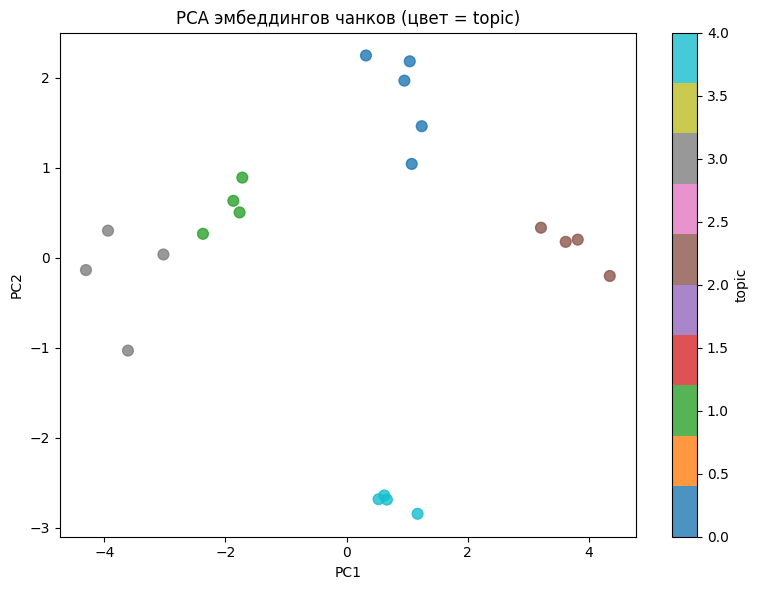

In [10]:
pca = PCA(n_components=2, random_state=42)
E_pca = pca.fit_transform(E)

plt.figure(figsize=(8,6))
scatter = plt.scatter(E_pca[:,0], E_pca[:,1], c=chunks['topic'], cmap='tab10', s=60, alpha=0.8)
plt.colorbar(scatter, label='topic')
plt.title('PCA эмбеддингов чанков (цвет = topic)')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.tight_layout(); plt.show()

Видны ли кластеры: да, на PCA-плоскости чанки группируются по темам — пять компактных облаков, соответствующих пяти topic. Это ожидаемо, так как генератор строил эмбеддинги как «центр темы + гауссов шум». Кластеры совпадают с темами, хотя возможны небольшие перекрытия из-за шума σ=0.4.